# Klasifikacija slika (ASL) pomoću CNN i augmentacije podataka

U prethodnom *notebook*-u smo trenirali CNN model umesto potpuno povezane neuronske mreže i videli da nam je to donelo uvećanje performansi.

Da bi model bio robustniji na manje različitosti u podacima test skupa u odnosu na podatke trening skupa, veštački ćemo uvećati veličinu i varijabilnost našeg skupa podatak primenom [augmentacije podataka](https://link.springer.com/article/10.1186/s40537-019-0197-0). Uvećanje veličine skupa podataka daje modelu više slika za trening, a uvećanje varijabilnosti pomaže modelu da ignoriše nevažna obeležja i da se fousira na ona bitna za klasifikaciju, što unapređuje generalizaciju.

U ovom *notebook*-u ćemo:
* Augmentovati ASL skup podataka
* Iskoristićemo augmentovane podatke da treniramo unapređeni model
* Snimićemo trenirani model na disk da bismo ga koristili u *deployment*-u.

## Priprema podataka

In [1]:
import tensorflow.keras as keras
import pandas as pd

# Load in our data from CSV files
train_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/asl_data/sign_mnist_train.csv")
test_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/asl_data/sign_mnist_valid.csv")

# Separate out our target values
y_train = train_df['label']
y_test = test_df['label']
del train_df['label']
del test_df['label']

# Separate our our image vectors
x_train = train_df.values
x_test = test_df.values

# Turn our scalar targets into binary categories
num_classes = 24
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

# Normalize our image data
x_train = x_train / 255
x_test = x_test / 255

# Reshape the image data for the convolutional network
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

In [2]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

## Kreiranje modela

In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Conv2D,
    MaxPool2D,
    Flatten,
    Dropout,
    BatchNormalization,
)

model = Sequential()
model.add(Conv2D(75, (3, 3), strides=1, padding="same", activation="relu",
                 input_shape=(28, 28, 1)))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2), strides=2, padding="same"))
model.add(Conv2D(50, (3, 3), strides=1, padding="same", activation="relu"))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2), strides=2, padding="same"))
model.add(Conv2D(25, (3, 3), strides=1, padding="same", activation="relu"))
model.add(BatchNormalization())
model.add(MaxPool2D((2, 2), strides=2, padding="same"))
model.add(Flatten())
model.add(Dense(units=512, activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(units=num_classes, activation="softmax"))

## Augmentacija podataka

Pre kompajliranja modela, podesićemo augmentaciju skupa podataka. Za ove potrebe, Keras obezbeđuje klasu [`ImageDataGenerator`](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator). Ova klasa prima [listu opcija](https://www.analyticsvidhya.com/blog/2020/08/image-augmentation-on-the-fly-using-keras-imagedatagenerator/) za augmentovanje podataka. Kasnije ćemo odabrati odgovarajuću strategiju augmentacije. Za sada ćemo primeniti sledeće:

In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,  # rotiraj sliku za nasumični ugao u opsegu -10-10 stepeni
    zoom_range=0.1,  # nasumično zumiraj sliku. Možemo navesti opseg ili samo jedan argument kao ovde da bude nasumični zoom u opsegu [1-zoom_range,1+zoom_range]
    width_shift_range=0.1,  # nasumično transliraj sliku horizontalno (procenat ukupne širine)
    height_shift_range=0.1,  # nasumično transliraj sliku vertikalno (procenat ukupne visine)
    horizontal_flip=True,  # nausmično flip-uj sliku horizontalno
    vertical_flip=False, # nemoj nasumično flip-ovati sliku vertikalno
)

Primetite da nismo dozvolili modelu da flipuje sliku po vertikalnoj osi. Razlog je što naš skup podataka sadrži slike ruku koje pokazuju slova alfabeta. Kada budemo primenjivali model u praksi, nije verovatno da će ruke biti naopačke. Sa druge strane, neki ljudi mogu biti levoruki. Ovo nam ukazuje da augmentacija mora biti domenski-specifična (prilagođena konkretnom problemu).

## Batch Size

Još jedan benefit klase `ImageDataGenerator` je što *batch*)-uje podatke tako da se model može trenirati na nasumičnom uzorku skupa podataka.

***Batch*** - broj primera koji se koriste za ažuriranje težina modela (tipično, neki stepen broja 2 (32, 64,...)). *Batch* veličine 32 znači da će se 32 slike iz trening skupa iskoristiti za estimaciju gradijenta greške, pre nego što se težine ažuriraju. U svakom koraku treniranja, model će selektovati novi *batch*. Ako je uzorak skupa podataka [zaista nasumičan](http://sites.utexas.edu/sos/random/) (podaci su nasumično izmešani), *batch* uzorak će dobro reprezentovati podatke iako predstavlja njihov manji deo.

**Epoha** - jedna trening epoha znači da će algoritam napraviti jedan prolaz kroz ceo skup podataka, gde su primeri razvrstani nasumično u *batch size* grupe. Zavisno od konfiguracije, može da bude jedan ili više *batch*-eva po epohi:
* *Batch gradient descent*: ceo skup podataka je jedinstventi *batch*.
* *Stohastic/online gradient descent*: *batch* je samo jedna instanca iz skupa podataka.
* *Minibatch gradient desent*: veličina *batch*-a je između ova dva ekstrema. Pošto su skupovi podataka za treniranje modela dubokih neuronskih mreža veoma veliki, u praksi se tipično koristi *minibatch*. Korišćenje *minibatch* ima dva poželjna efekta:
    * Nasumični manji skupovi rezultuju efektom regularizacije i smanjenjenjem generalizacione greške.
    * Manja veličina *batch*-a omogućuje da neophodni podaci stanu u memoriju sa kojom raspolažemo. Maksimalna vrednost `batch_size` može biti ograničena ako vaš model + skup podataka ne staju u raspoloživu (GPU) memoriju.

**Iteracija** - broj *batch*-eva neophodan da se izvrši jedna epoha. Na primer, ako skup podataka sadrži 10 000 instanci, podeljenih u 20 *batch*-eva, treba nam 500 iteracija (10 000 = 500 * 20) da prođemo kroz jednu epohu.

Dobra podrazumevana vrednost veličine *batch*-a je 32, ali je ovo takođe hiper-parametar sa kojim [vredi eksperimentisati](https://arxiv.org/abs/1804.07612). Pogrešan *batch size* može učiniti da *underfit*-ujete, *overfit*-ujete ili ne koristite memoriju optimalno. Za više detalja, pročitajte [ovaj](https://machinelearningmastery.com/how-to-control-the-speed-and-stability-of-training-neural-networks-with-gradient-descent-batch-size/) i [ovaj](https://blog.paperspace.com/how-to-maximize-gpu-utilization-by-finding-the-right-batch-size/) članak.

Izvršite kod ispod i pogledajte rezultate da vidite kako izgleda jedan *batch*. Da li je izbor slova zaista nasumičan? Da li su augmentovane slike prepoznatljiva ASL slova?

(32, 28, 28, 1)
[[0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]]


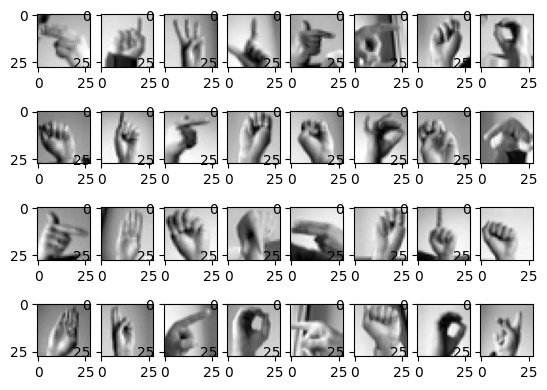

In [5]:
import matplotlib.pyplot as plt
import numpy as np
batch_size = 32
img_iter = datagen.flow(x_train, y_train, batch_size=batch_size)

x, y = img_iter.next()
print(x.shape)
print(y[0:3])

fig, ax = plt.subplots(nrows=4, ncols=8)
for i in range(batch_size):
    image = x[i]
    ax.flatten()[i].imshow(np.squeeze(image), cmap='gray') #squeeze - (28, 28, 1) -> (28, 28)
plt.show()

Generator moramo *fit*-ovati na trening skup. Nakon toga možemo kompajlirati model:

In [6]:
datagen.fit(x_train)

In [7]:
from tensorflow.keras import backend as K

def f1_score(y_true, y_pred):
    # Calculating Precision and Recall
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))

    precision = true_positives / (predicted_positives + K.epsilon())
    recall = true_positives / (possible_positives + K.epsilon())

    # Calculating F1 Score
    f1_val = 2*(precision*recall)/(precision+recall+K.epsilon())

    return f1_val

In [8]:
model.compile(loss='categorical_crossentropy', metrics=[f1_score])

## Trening sa augmentacijom

Kada koristimo *Keras*-ov generator podataka, treniramo model nešto drugačije - umesto da prosledimo `x_train` i `y_train`, prosleđujemo generator koristeći njegovu [`flow`](https://keras.io/api/preprocessing/image/) metodu. Ovo čini da slika bude "uživo" augmentovana u memoriji neposredno pre njenog prosleđivanja modelu.

Generatori mogu da proizvedu neograničenu količinu podataka, pa, prilikom treniranja, moramo eksplicitno podesiti koliko želimo da se epoha izvršava ili će izvršavanje epohe trajati beskonačno. Ovo podešavamo kroz `steps_per_epoch`, što je broj *batch* iteracija pre nego što kažemo da je epoha završena. Ako imate skup podataka fiksne veličine, možete ignorisati ovaj parametar, međutim, koristan je ako imate ogroman skup podataka ili neograničen skup podataka kao u slučaju augmentacije.

Pošto važi `steps` * `batch_size` = `number_of_images_trained_in_an_epoch`, tipična praksa (koju ćemo ovde primeniti) je da podesimo broj iteracija da bude jednak veličini ne-augmenotvanog skupa podataka podeljenog sa `batch_size` (kod nas podrazumevano 32).

In [9]:
history = model.fit(img_iter,
          epochs=40,
          steps_per_epoch=len(x_train)/batch_size, # Run same number of steps we would if we were not using a generator.
          validation_data=(x_val, y_val))

Epoch 1/40
686/686 [==============================] - 19s 19ms/step - loss: 1.2162 - f1_score: 0.5739 - val_loss: 1.1454 - val_f1_score: 0.6120
Epoch 2/40
686/686 [==============================] - 14s 20ms/step - loss: 0.3729 - f1_score: 0.8719 - val_loss: 0.2614 - val_f1_score: 0.9094
Epoch 3/40
686/686 [==============================] - 13s 20ms/step - loss: 0.2339 - f1_score: 0.9214 - val_loss: 0.4332 - val_f1_score: 0.8775
Epoch 4/40
686/686 [==============================] - 13s 18ms/step - loss: 0.1731 - f1_score: 0.9418 - val_loss: 0.1356 - val_f1_score: 0.9480
Epoch 5/40
686/686 [==============================] - 14s 20ms/step - loss: 0.1396 - f1_score: 0.9538 - val_loss: 0.0184 - val_f1_score: 0.9939
Epoch 6/40
686/686 [==============================] - 13s 19ms/step - loss: 0.1264 - f1_score: 0.9612 - val_loss: 0.0358 - val_f1_score: 0.9876
Epoch 7/40
686/686 [==============================] - 11s 16ms/step - loss: 0.1042 - f1_score: 0.9674 - val_loss: 0.1493 - val_f1_score:

Vizualizacija trening i validacione tačnosti kroz epohe:

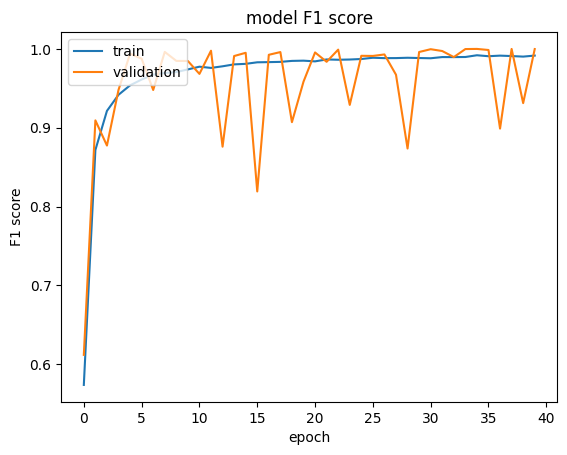

In [13]:
import matplotlib.pyplot as plt
plt.plot(history.history['f1_score'])
plt.plot(history.history['val_f1_score'])
plt.title('model F1 score')
plt.ylabel('F1 score')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [14]:
# Evaluate the model on test data
test_loss, test_f1_score = model.evaluate(x_test, y_test, verbose=0)

print("F1 Score on Test Data:", test_f1_score)

F1 Score on Test Data: 0.9996516704559326


## Čuvanje modela
Kada imamo trenirani model kojim smo zadovoljni, možemo ga sačuvati na disk. Kodistićemo *Keras*-ovu [`save`](https://www.tensorflow.org/guide/keras/save_and_serialize) metodu. U sledećem *notebook*-u učitaćemo ovaj trenirani model i primenjivaćemo ga na novim (test) slikama.

In [15]:
model.save('/content/drive/MyDrive/Colab Notebooks/CNN vežbe/data/asl_data/asl_model')